# Profile likelihood of the free parameters

For every free parameter $\theta_i$ two arms leave the estimate (up and down), each with `profile_points` points over
`profile_span` decades (clipped to the bounds). At every point $\theta_i$ is fixed and the other free parameters are
re-optimized, warm started at the previous point, plus `profile_extra_starts` starts around it. A point that a point
farther out on its arm beats by more than $\Delta$ missed the minimum, so it is refitted backward from the theta of the next
point farther out. With $N$ conditions the parmest objective is $\frac{1}{N}\sum_c \frac{1}{2}\chi^2_c$, so the
likelihood-ratio threshold at level `lr_alpha` is $\Delta = \chi^2_{1,\alpha}/(2N)$. An arm crosses where it reaches
$\hat g + \Delta$ and stays above it farther out. A parameter is *identifiable* if both arms cross, *one sided* if one arm
does, *flat* if none does. Code: `src/uncertainty/profiles.py`.

In [1]:
import os
import sys
import json
import logging
import warnings

HERE = os.getcwd()
REPO = os.path.dirname(HERE) if os.path.basename(HERE) == "notebooks" else HERE
for path in (os.path.join(REPO, "notebooks"), os.path.join(REPO, "src")):
    if path not in sys.path:
        sys.path.insert(0, path)

import settings  # noqa: F401  (pins BLAS / OpenMP to one thread before numpy is loaded)
from paths import resolve_out

OUT = resolve_out(os.environ.get("HK_OUT") or settings.METHOD["out_dir"])
RUN = os.environ.get("HK_RUN", "0") == "1"

warnings.filterwarnings("ignore")
logging.getLogger("pyomo").setLevel(logging.ERROR)
print("OUT :", OUT)
print("RUN :", RUN, "(False: load the saved results of OUT; True: compute and save into OUT)")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 40)

from uncertainty import profiles

FINAL = os.path.join(OUT, "final")
PROF = os.path.join(OUT, "profiles")

OUT : /Users/gabbi/Desktop/Repos/HybridKinetics-IIQ3733/results/flux_model
RUN : False (False: load the saved results of OUT; True: compute and save into OUT)


In [2]:
# Settings of the method (defaults from settings/method.csv)
params = settings.default_params()
params["n_jobs"] = int(os.environ.get("HK_N_JOBS", params["n_jobs"]))
params

{'n_starts': 50,
 'seed': 0,
 'structural_q': 10,
 'structural_tol': 1e-10,
 'rank_tol': 0.0001,
 'corr_threshold': 0.9,
 'lr_alpha': 0.95,
 'bootstrap_n': 5000,
 'bootstrap_ci_ratio': 10.0,
 'bootstrap_local_starts': 5,
 'bootstrap_local_span': 1.0,
 'profile_points': 30,
 'profile_span': 1.0,
 'profile_extra_starts': 3,
 'profile_extra_span': 1.0,
 'bootstrap_profile_seeds': 3,
 'n_jobs': 10,
 'out_dir': 'results/flux_model'}

In [3]:
if RUN:
    profiles.run_profiles(FINAL, PROF, params)
else:
    print("RUN is False: the profiles are loaded from", PROF)

RUN is False: the profiles are loaded from /Users/gabbi/Desktop/Repos/HybridKinetics-IIQ3733/results/flux_model/profiles


In [4]:
thresholds = json.load(open(os.path.join(PROF, "profile_thresholds.json")))
summary = pd.read_csv(os.path.join(PROF, "profile_summary.csv"), index_col=0)
points = pd.read_csv(os.path.join(PROF, "profiles_all.csv"))
print("threshold %.4f above the best objective %.5f" % (thresholds["lr_threshold"], thresholds["obj_hat"]))
summary.round(4)

threshold 0.0873 above the best objective 10.90428


,estimate,upper_decades,lower_decades,profile_class,n_failed,max_dobj_up,max_dobj_down
param,,,,,,,
v_max_1,80.2561,NaN,0.2278,one_sided,0,0.0554,34.7746
Ks_g6p_pgi,0.0050,NaN,NaN,flat,0,0.0552,0.0546
kcat_f_2,978.1748,NaN,0.2580,one_sided,0,0.0406,0.7006
kcat_f_3,974.4076,NaN,0.0703,one_sided,0,0.0229,42.8000
Ks_fbp_4,0.0010,0.2770,NaN,one_sided,0,0.7203,0.0606
kcat_f_4,2.6973,0.0165,0.0236,identifiable,0,29.7917,42.6117
kcat_f_5,6865.9168,NaN,NaN,flat,0,0.0560,0.0676
kcat_f_6,622.6176,0.2311,NaN,one_sided,0,0.0901,0.0233
kcat_f_7,875.8411,NaN,0.8229,one_sided,0,0.0479,0.1625


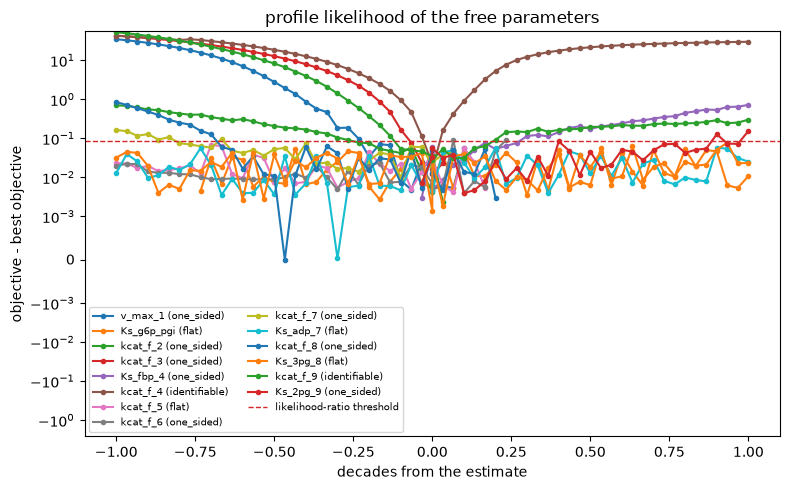

In [5]:
fig, ax = plt.subplots(figsize=(8, 5))
for name in summary.index:
    rows = points[points["param"] == name].sort_values("log10_offset")
    ax.plot(rows["log10_offset"], rows["obj"] - thresholds["obj_hat"], "o-", ms=3,
            label="%s (%s)" % (name, summary.loc[name, "profile_class"]))
ax.axhline(thresholds["lr_threshold"], color="tab:red", ls="--", lw=1, label="likelihood-ratio threshold")
ax.set_yscale("symlog", linthresh=1e-3)
ax.set_xlabel("decades from the estimate")
ax.set_ylabel("objective - best objective")
ax.legend(fontsize=7, ncol=2)
ax.set_title("profile likelihood of the free parameters")
fig.tight_layout()
plt.show()